In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = pd.read_csv('../data/raw/cs-training.csv', index_col=0)
sns.set_theme(style="whitegrid")

In [2]:
data.info()
print(f"\nShape: {data.shape}")

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [3]:
data.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


# Анализ целевой переменной

Количество и процент людей вернувших/не вернувших кредит:


,Количество,Процент
SeriousDlqin2yrs,,
0,139974,93.32
1,10026,6.68


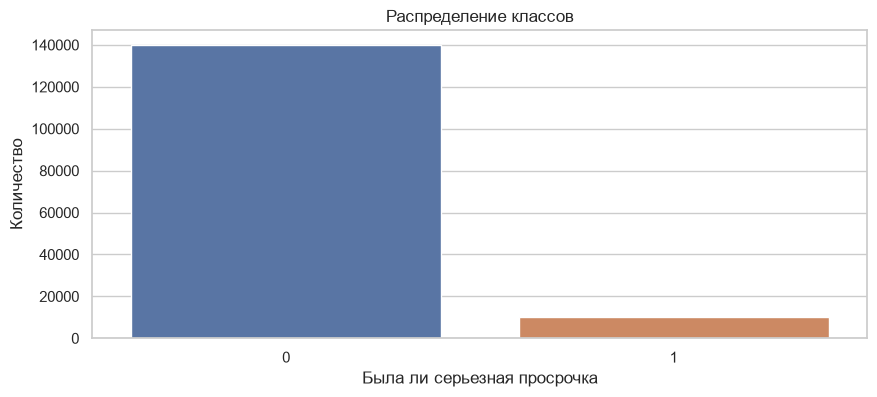

In [4]:
percentages = (data['SeriousDlqin2yrs'].value_counts(normalize=True) * 100).round(2)
targetVar_table = pd.concat([data['SeriousDlqin2yrs'].value_counts(), percentages], axis=1)
targetVar_table.columns = ['Количество', 'Процент']
print("Количество и процент людей вернувших/не вернувших кредит:")
display(targetVar_table)

plt.figure(figsize=(10, 4))
sns.countplot(x='SeriousDlqin2yrs', data=data, hue='SeriousDlqin2yrs', legend=False)
plt.title("Распределение классов")
plt.xlabel("Была ли серьезная просрочка")
plt.ylabel("Количество")
plt.show()

### Вывод по анализу целевой переменной:

1. **Фактическое распределение:**
   * Класс 0 (клиенты без просрочки): **139 974** заёмщика (**93.32%**).
   * Класс 1 (дефолт / просрочка 90+ дней): **10 026** заёмщиков (**6.68%**).
   * Соотношение классов составляет примерно **14 : 1**.

2. **Проблема:**
   * Присутствует сильный дисбаланс классов => метрика **Accuracy** не подходит, так как если модель будет предсказывать всем 0, то ее точность будет **93.32%**, но банк не поймет ни одного дефолтного клиента.

3. **Решения:**
   * **Метрика:** Основной метрикой для оценки моделей выбираем **ROC-AUC**, так как она показывает способность модели ранжировать клиентов от надежных к рискованным независимо от баланса классов. Дополнительно будем отслеживать **PR-AUC** и **F1-score** по классу 1.
   * **Валидация:** При разбиении на обучающую и валидационную выборки необходимо использовать **стратификацию**, чтобы в каждой части сохранялась исходная пропорция дефолтов (~6.7%).
   * **Обучение:** При обучении базовых моделей потребуется использовать взвешивание классов.

# Анализ распределений и числовых характеристик

In [5]:
data.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.0,0.000000,0.000000,1.0,1.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.0,0.000000,0.154181,1.0,1.092956,50708.0
age,150000.0,52.295207,14.771866,0.0,24.0,29.000000,52.000000,78.0,87.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.0,0.000000,0.000000,2.0,4.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.0,0.004329,0.366508,2449.0,4979.040000,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,0.0,1300.000000,5400.000000,14587.6,25000.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,0.0,2.000000,8.000000,18.0,24.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.0,0.000000,0.000000,1.0,3.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.0,0.000000,1.000000,3.0,4.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.0,0.000000,0.000000,1.0,2.000000,98.0


In [6]:
missing_info = data.isnull().sum()
missing_info_percent = (data.isnull().mean() * 100).round(2)
missing_table = pd.concat([missing_info, missing_info_percent], axis=1)
missing_table.columns = ['Количество пропусков', 'Процент пропусков']
missing_table = (missing_table[missing_table['Количество пропусков'] > 0]
                 .sort_values(by='Количество пропусков', ascending=False))

print("Количество пропусков и процент:")
display(missing_table)

Количество пропусков и процент:


,Количество пропусков,Процент пропусков
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


In [7]:
print(f"Количество людей с возрастом 0: {(data['age'] == 0).sum()}")

print("\nСамые частые значения просрочек 30-59 дней в верхнем хвосте:")
display(data['NumberOfTime30-59DaysPastDueNotWorse'].value_counts().sort_index().tail(10))

print("\nСамые частые значения просрочек 60-89 дней в верхнем хвосте:")
display(data['NumberOfTime60-89DaysPastDueNotWorse'].value_counts().sort_index().tail(10))

print("\nСамые частые значения просрочек более 90 дней в верхнем хвосте:")
display(data['NumberOfTimes90DaysLate'].value_counts().sort_index().tail(10))


Количество людей с возрастом 0: 1

Самые частые значения просрочек 30-59 дней в верхнем хвосте:


NumberOfTime30-59DaysPastDueNotWorse
6     140
7      54
8      25
9      12
10      4
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64


Самые частые значения просрочек 60-89 дней в верхнем хвосте:


NumberOfTime60-89DaysPastDueNotWorse
3     318
4     105
5      34
6      16
7       9
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64


Самые частые значения просрочек более 90 дней в верхнем хвосте:


NumberOfTimes90DaysLate
9      19
10      8
11      5
12      2
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64

In [8]:
print("Топ-10 максимальных значений RevolvingUtilization:")
display(data['RevolvingUtilizationOfUnsecuredLines'].nlargest(10))

util = data['RevolvingUtilizationOfUnsecuredLines']
print(f"Клиентов с утилизацией > 1, но < 3 (больше 100% лимита): {((util > 1) & (util < 3)).sum()} ({((util > 1) & (util < 3)).mean()*100:.2f}%)")
print(f"Клиентов с утилизацией > 10 (больше 1000% лимита): {(util > 10).sum()} ({(util > 10).mean()*100:.2f}%)")
print(f"Клиентов с утилизацией > 100 (больше 10000% лимита): {(util > 100).sum()} ({(util > 100).mean()*100:.2f}%)")

Топ-10 максимальных значений RevolvingUtilization:


85490     50708.0
31415     29110.0
16957     22198.0
149161    22000.0
149280    20514.0
117316    18300.0
21979     17441.0
124534    13930.0
72593     13498.0
71706     13400.0
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

Клиентов с утилизацией > 1, но < 3 (больше 100% лимита): 3029 (2.02%)
Клиентов с утилизацией > 10 (больше 1000% лимита): 241 (0.16%)
Клиентов с утилизацией > 100 (больше 10000% лимита): 223 (0.15%)


Медиана DebtRatio у людей без дохода: 1159.0
Медиана DebtRatio у людей с доходом: 0.296022604
Максимальные значения DebtRatio у людей с доходом:
18229     12778.0
24683     14969.0
91        15466.0
25864     20000.0
66930     20809.0
63856     25033.0
19362     25801.0
146311    49112.0
127899    60212.0
53683     61106.5
Name: DebtRatio, dtype: float64
Квантили DebtRatio для людей с доходом:
0.900       0.763149
0.950       1.128771
0.975       2.332667
0.980       4.500000
0.990     661.820000
0.995    1781.830000
0.999    4323.588000
Name: DebtRatio, dtype: float64
Максимальные значения DebtRatio у людей без дохода:
46103      52112.0
66786      61907.0
69846     101320.0
103042    106885.0
7514      110952.0
4855      168835.0
58901     220516.0
127048    307001.0
36601     326442.0
60153     329664.0
Name: DebtRatio, dtype: float64
Квантили DebtRatio для людей без дохода:
0.9000      3785.000
0.9500      4902.500
0.9750      6099.250
0.9800      6560.400
0.9900      8084.500
0.99

,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,DebtRatio
7,8,3,5710.0
9,2,0,46.0
17,10,2,2058.0
33,6,1,977.0
42,7,0,75.0


Проверка корреляции(метод Спирмена) между признаками:


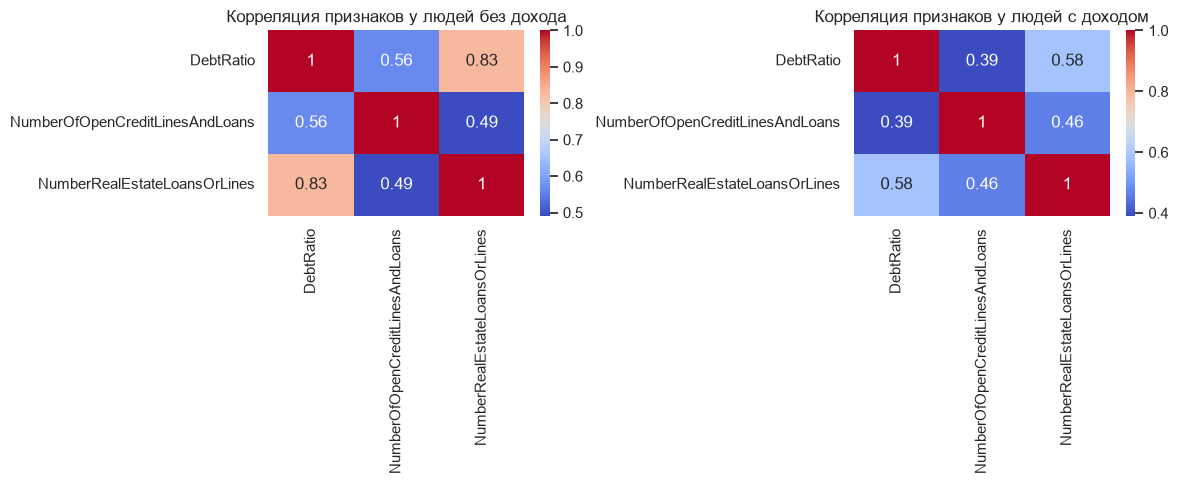

In [9]:
print(
    'Медиана DebtRatio у людей без дохода:',
    data[data['MonthlyIncome'].isna()]['DebtRatio'].median()
)
print(
    'Медиана DebtRatio у людей с доходом:',
    data[data['MonthlyIncome'].notna()]['DebtRatio'].median()
)
print(
    'Максимальные значения DebtRatio у людей с доходом:',
    data[data['MonthlyIncome'].notna()]['DebtRatio'].sort_values().tail(10),
    sep='\n'
)
print(
    'Квантили DebtRatio для людей с доходом:',
    data[data['MonthlyIncome'].notna()]['DebtRatio'].quantile([0.9, 0.95, 0.975, 0.98, 0.99, 0.995, 0.999]),
    sep='\n'
)
print(
    'Максимальные значения DebtRatio у людей без дохода:',
    data[data['MonthlyIncome'].isna()]['DebtRatio'].sort_values().tail(10),
    sep='\n'
)
print(
    'Квантили DebtRatio для людей без дохода:',
    data[data['MonthlyIncome'].isna()]['DebtRatio'].quantile([0.9, 0.95, 0.975, 0.98, 0.99, 0.995, 0.999, 0.9999]),
    sep='\n'
)

no_income = data[data['MonthlyIncome'].isna()]
print('Количество открытых кредитов у людей без дохода:')
display(no_income[['NumberOfOpenCreditLinesAndLoans', 'NumberRealEstateLoansOrLines', 'DebtRatio']].head())

print('Проверка корреляции(метод Спирмена) между признаками:')
cols = [
    'DebtRatio', 
    'NumberOfOpenCreditLinesAndLoans',
    'NumberRealEstateLoansOrLines'
]
corr_no_income = (
    data[data['MonthlyIncome'].isna()][cols].corr(method='spearman').round(3)
)
corr_with_income = (
    data[data['MonthlyIncome'].notna()][cols].corr(method='spearman').round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(corr_no_income, annot=True, cmap='coolwarm', ax=axes[0])
axes[0].set_title('Корреляция признаков у людей без дохода')
sns.heatmap(corr_with_income, annot=True, cmap='coolwarm', ax=axes[1])
axes[1].set_title('Корреляция признаков у людей с доходом')
plt.tight_layout()
plt.show()

### Пропуски:
* Столбец **MonthlyIncome** имеет 29731 пропусков (**19.82**%) и **NumberOfDependents** имеет 3924 пропусков (**2.62**%).
* Пропуски в **NumberOfDependents** могут говорить о том, что у людей 0 иждивенцев.
* Пропуски в **MonthlyIncome** могут говорить о самозанятости, безработице, неофициальном доходе.
  
### Решение:
* Удалить данные не можем, так как теряем достаточно высокий процент данных.
* В **NumberOfDependents** можем заполнить данные медианой/модой
* В **MonthlyIncome** заполним медианой, так как зарплаты имеют сильные перекосы из-за более обеспеченных людей. А также создадим бинарный признак `MonthlyIncome_is_missing`, который будет равен **1**, если был пропуск и **0** иначе. Так модель не потеряет информацию о скрытии дохода клиентом.

### Числовые характеристики:
* **age:** min = 0 (1 запись), а также max = 109. Это не является корректными данными для возраста.
  * **Решение:** сверху возраст лучше ограничить (прижать) до 100, а нуль заменить на медианный возраст.
* **NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse, NumberOfTimes90DaysLate:** Данные соответственно max = 98; 98; 98, хотя 99-квантиль = 4; 2; 3. Наблюдается скачок с нормальных значений на 96(5 записей) и 98(264 записи).
  * **Решение:**
    * создать бинарный признак `has_past_due_anomaly` для сохранения информации о сбое в данных.
    * А также заменить значения 96 и 98 на медиану, чтобы исключить искажение весов.
* **RevolvingUtilizationOfUnsecuredLines:** max = 50708, то есть клиент превысил кредитный лимит в 50000 раз. Также тех, чье превышение лежит от 1 до 3, составило 3029(**2.02**%) - это реальный сигнал, что человек исчерпал лимит.
  * **Решение:** значения выше разумного порога (например, > 2-3 или отсечению по 99.8-квантилю) ограничить сверху (прижать), чтобы исключить экстремальные технические выбросы, но сохранить информацию о клиентах с реальным превышением лимита.
* **DebtRatio:** У людей с доходом ~**30**%, а у людей без дохода **1159** неизвестных единиц. Когда у людей нет дохода, нет на что делить в формуле DebtRatio.
  * **Гипотеза:** Большие значения у людей без дохода являются записью о ежемесячном платеже.
  * **Подтверждение:** Матрица корреляций методом Спирмена показала, что у людей без дохода корреляция между `DebtRatio` и `NumberRealEstateLoansOrLines` (ипотеки) равна **0.83**. Это почти прямая связь. А у людей с доходом **0.58**, потому что там долг еще делится на разную зарплату клиентов. Между `DebtRatio` и `NumberOfOpenCreditLinesAndLoans` (все кредиты): Без дохода связь **0.56**, а с доходом **0.39**.
  * **Решение:** Смешаны две разные физические величины: относительный коэффициент и абсолютная сумма ежемесячного платежа. 
    * Создать бинарный флаг `MonthlyIncome_is_missing` (маркер того, что `DebtRatio` измеряется в долларах).
    * На основе известных `MonthlyIncome` и `DebtRatio` для первой группы можно рассчитать сам ежемесячный платеж `MonthlyPayment = DebtRatio * MonthlyIncome`.
    * Для заемщиков с доходом 95-квантиль ~**1.13**, 97.5-квантиль ~**2.33**. После 98-квантиля происходит скачок (**4.5** => **661.8**). Порог для ограничения сверху (прижатия) примерно **2.5 - 4.5**.
    * Для заемщиков без дохода до 99.5-квантиля платежи лежат в пределах разумного (до ~**10000**), а значения выше (до max = **329664**) являются выбросами. Ограничение сверху (прижатие) производим по 99.5-квантилю.
* **NumberOfOpenCreditLinesAndLoans** и **NumberRealEstateLoansOrLines:** имеют естественные гладкие распределения без системных кодов ошибок (медианы 8 и 1 соответственно). Редкие крупные значения (максимумы 58 и 54) соответствуют реальным заёмщикам с большими кредитными портфелями и не требуют действий.

# Исследовательская визуализация данных

## Правда ли, что молодые заёмщики чаще выходят на дефолт, а с возрастом платёжная дисциплина растёт?

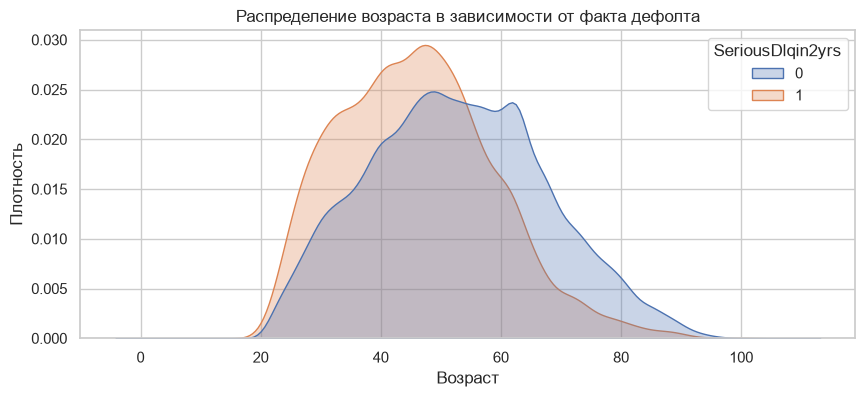

In [10]:
plt.figure(figsize=(10, 4))
sns.kdeplot(x='age', data=data, hue='SeriousDlqin2yrs', common_norm=False, fill=True, alpha=0.3)
plt.title('Распределение возраста в зависимости от факта дефолта')
plt.xlabel('Возраст')
plt.ylabel('Плотность')
plt.show()

 * Распределение возраста для дефолтных заёмщиков (класс 1) смещено влево по сравнению с надёжными клиентами (класс 0). Пик дефолтов приходится на возрастной диапазон **~35–48 лет**.
 * Молодые заёмщики и клиенты среднего возраста несут повышенный кредитный риск (карьера и доходы могут быть менее стабильными, выше кредитная нагрузка на семью/детей). С увеличением возраста (особенно 55+) платёжная дисциплина клиентов заметно возрастает, а риск дефолта падает.
 * Признак `age` полезен сам по себе, но для моделей также может быть выгодно создать категориальные возрастные признаки: `young` (< 35), `middle` (35–55), `senior` (> 55).

## Правда ли, что даже одна краткосрочная задержка платежа (на 30–59 дней) в прошлом повышает вероятность выхода на критический дефолт (90+ дней) в будущем?

In [11]:
clean_past_due = data[data['NumberOfTime30-59DaysPastDueNotWorse'] < 90].copy()
clean_past_due['past_due_group'] = clean_past_due['NumberOfTime30-59DaysPastDueNotWorse'].clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'})
clean_past_due_grp = (
    clean_past_due
    .groupby('past_due_group')['SeriousDlqin2yrs']
    .mean()
    .reset_index(name='DefaultRate')
)
clean_past_due_grp['DefaultRate'] = clean_past_due_grp['DefaultRate'] * 100

display(clean_past_due_grp)

,past_due_group,DefaultRate
0,0,4.000222
1,1,15.025260
2,2,26.511527
3,3+,39.260221


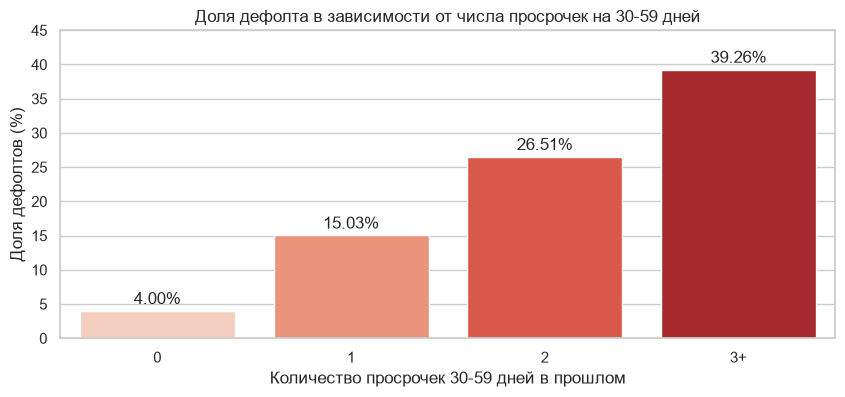

In [12]:
plt.figure(figsize=(10, 4))
ax = sns.barplot(data=clean_past_due_grp, x='past_due_group', y='DefaultRate', palette='Reds', hue='past_due_group', legend=False)
plt.title('Доля дефолта в зависимости от числа просрочек на 30-59 дней')
plt.xlabel('Количество просрочек 30-59 дней в прошлом')
plt.ylabel('Доля дефолтов (%)')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2.0, p.get_height() + 1.0), ha='center')

plt.ylim(0, 45)
plt.show()

1. 
   * У клиентов без задержек в прошлом (`0`) доля дефолта составляет всего **4.00%**.
   * При наличии всего **одной** задержки платежа вероятность дефолта резко подскакивает до **15.03%** (рост почти в **4 раза**).
   * При **2** просрочках риск достигает **26.51%** (рост в **6.5 раз**).
   * При **3 и более** просрочках вероятность дефолта составляет **39.26%**.

2.
   * Историческая платёжная дисциплина — один из сильнейших опережающих индикаторов риска в кредитном скоринге.
   * Даже разовая задержка платежа на 30–59 дней не является случайностью, а свидетельствует о начале финансовой нестабильности заёмщика. Для банка наличие хотя бы одного такого факта в БКИ — повод снизить кредитный лимит или передать заявку на ручную проверку.

3.
   * Признак обладает высокой прогностической силой.
   * На этапе подготовки данных полезно создать:
     1. Бинарный индикатор `has_30_59_past_due` (факт наличия хотя бы одного нарушения срока).
     2. Суммарный признак общего числа просрочек: `Total_Past_Due = NumberOfTime30-59... + NumberOfTime60-89... + NumberOfTimes90DaysLate`.


## Заёмщики, которые тратят почти весь кредитный лимит или выходят за его рамки, находятся в состоянии долгового стресса и выходят в дефолт в разы чаще тех, кто держит утилизацию на комфортном уровне.

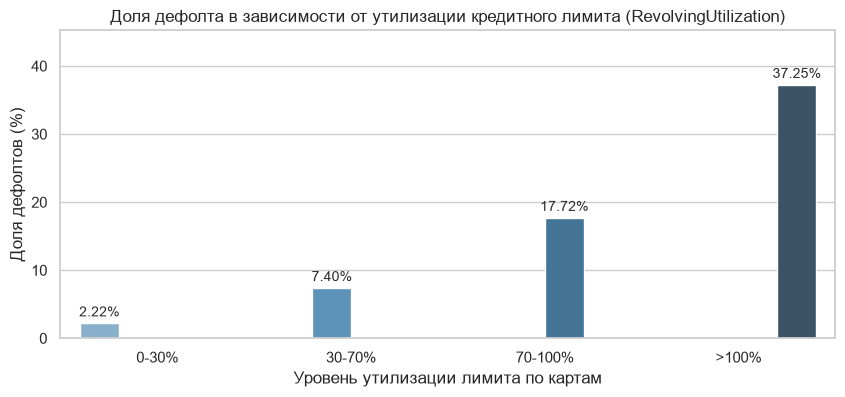

In [13]:
util_df = data[
    ['RevolvingUtilizationOfUnsecuredLines', 'SeriousDlqin2yrs']
].copy()

bins = [-0.01, 0.3, 0.7, 1.0, float('inf')]
labels = ['0-30%', '30-70%', '70-100%', '>100%']
util_df['util_group'] = pd.cut(
    util_df['RevolvingUtilizationOfUnsecuredLines'], bins=bins, labels=labels
)

util_grp = (
    util_df.groupby('util_group', observed=False)['SeriousDlqin2yrs']
    .mean()
    .reset_index(name='DefaultRate')
)
util_grp['DefaultRate'] = util_grp['DefaultRate'] * 100

plt.figure(figsize=(10, 4))
ax = sns.barplot(
    data=util_grp,
    x='util_group',
    y='DefaultRate',
    palette='Blues_d',
    hue='util_group',
    legend=False,
)

plt.title(
    'Доля дефолта в зависимости от утилизации кредитного лимита (RevolvingUtilization)'
)
plt.xlabel('Уровень утилизации лимита по картам')
plt.ylabel('Доля дефолтов (%)')

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}%',
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 1.0),
        ha='center',
        fontsize=10,
    )

plt.ylim(0, max(util_grp['DefaultRate']) + 8)
plt.show()

1. **Наблюдение (динамика риска):**
   * При низкой нагрузке на кредитные карты (до 30% лимита) уровень дефолта минимален — всего **2.22%**.
   * При умеренном использовании (30–70%) риск утраивается до **7.40%**.
   * В преддефолтной зоне (70–100% исчерпания лимита) доля дефолтов возрастает до **17.72%** (в 8 раз выше базового уровня).
   * При выходе за рамки кредитного лимита (>100%) дефолт наступает у **37.25%** заёмщиков (рост почти в **17 раз** относительно безопасной зоны).

2. **Бизнес-интерпретация:**
   * Коэффициент использования лимита — фундаментальный индикатор финансового состояния заёмщика.
   * Клиент, вычерпавший кредитку более чем на 70–80%, практически гарантированно гасит текущие бытовые расходы заёмными деньгами. Это состояние скрытого финансового кризиса, которое наступает ещё до появления первых реальных просрочек по кредитам.

3. **Рекомендации для Feature Engineering:**
   * Признак демонстрирует мощную монотонную зависимость с таргетом и войдёт в топ самых важных признаков любой модели.
   * На этапе подготовки данных:
     1. Создать бинарный индикатор превышения лимита: `is_overutilized = (RevolvingUtilizationOfUnsecuredLines > 1.0)`.
     2. Использовать разбиение на интервалы для построения линейного скоринга.

## Общая тепловая карта корреляций

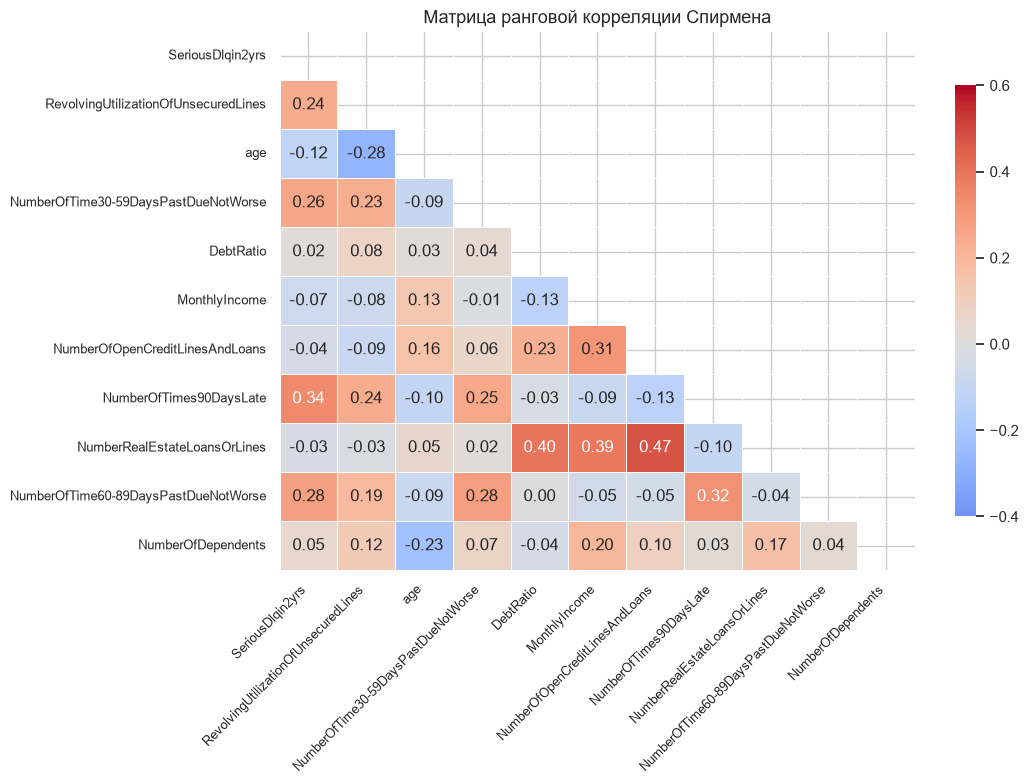

Корреляция признаков с целевой переменной SeriousDlqin2yrs (по модулю):


NumberOfTimes90DaysLate                 0.342
NumberOfTime60-89DaysPastDueNotWorse    0.277
NumberOfTime30-59DaysPastDueNotWorse    0.257
RevolvingUtilizationOfUnsecuredLines    0.240
age                                     0.117
MonthlyIncome                           0.067
NumberOfDependents                      0.046
NumberOfOpenCreditLinesAndLoans         0.039
NumberRealEstateLoansOrLines            0.034
DebtRatio                               0.021
Name: SeriousDlqin2yrs, dtype: float64

In [14]:
import numpy as np

corr = data.corr(method='spearman')

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-0.4,
    vmax=0.6,
    cbar_kws={'shrink': 0.8},
    linewidths=0.5,
)

plt.title('Матрица ранговой корреляции Спирмена', fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

print('Корреляция признаков с целевой переменной SeriousDlqin2yrs (по модулю):')
display(corr['SeriousDlqin2yrs'].drop('SeriousDlqin2yrs').abs().sort_values(ascending=False).round(3))

1. **Ключевые предикторы риска:**
   * Наибольшую корреляцию с целевой переменной `SeriousDlqin2yrs` демонстрируют признаки прошлых просрочек: `NumberOfTimes90DaysLate` (**0.342**), `NumberOfTime60-89...` (**0.277**) и `NumberOfTime30-59...` (**0.257**).
   * Четвёртым по важности признаком является утилизация кредитного лимита `RevolvingUtilizationOfUnsecuredLines` (**0.240**).
   * Признак возраста `age` имеет статистически значимую отрицательную корреляцию (**-0.117**), что подтверждает снижение риска дефолта с увеличением возраста заёмщика.

2. **Мультиколлинеарность:**
   * Обнаружена умеренная взаимная корреляция между тремя признаками просрочек (0.25–0.32), а также между числом ипотек и общим количеством кредитных линий (0.47).
   * *Для линейных моделей* мультиколлинеарность просрочек может вызывать нестабильность весов, поэтому имеет смысл объединить их в единый агрегированный скор.

3. **Слабая линейная корреляция DebtRatio и MonthlyIncome:**
   * Практически нулевая корреляция `DebtRatio` (0.021) с таргетом объясняется смешением двух режимов (проценты и доллары) и наличием экстремальных выбросов. Аналогично `MonthlyIncome` (0.067) ослаблен 20% пропусков.
   * Это доказывает необходимость нелинейного Feature Engineering, так как в сыром виде эти признаки не раскрывают свой потенциал.

# Итоговое резюме EDA и план предобработки

В ходе разведочного анализа данных сформирован следующий план действий для этапа моделирования (`02_baseline.ipynb`):

1. **Разбиение данных и валидация:**
   * Из-за дисбаланса 93.3% / 6.7% использовать **Stratified K-Fold** (5 фолдов).
   * Основная метрика — **ROC-AUC**; дополнительно фиксировать **PR-AUC** и **F1-score**.

2. **Обработка пропусков:**
   * `NumberOfDependents` (2.62%): заполнить медианой / модой (`0`).
   * `MonthlyIncome` (19.82%): заполнить медианой обучающей выборки (`5 400`) + создать бинарный признак `MonthlyIncome_is_missing = 1`.

3. **Обработка аномалий и клиппинг:**
   * `age`: значение `0` заменить медианой (`52`), ограничить сверху порогом `100`.
   * Признаки просрочек: создать бинарный флаг системного сбоя `has_past_due_anomaly = 1` для записей со значениями 96 и 98, а сами значения в исходных столбцах заменить на `0`.
   * `RevolvingUtilizationOfUnsecuredLines`: применить клиппинг по верхнему порогу (2.0–3.0) для устранения артефактов до 50 000.
   * `DebtRatio`: клиппировать группу с доходом по порогу ~2.5–4.5, группу без дохода — по порогу ~10 000$.